# Homework 4: Metrics (Lead Scoring 2026)

Target: `converted` (apakah lead mendaftar ke platform). Dataset: `data/course_lead_scoring_2026.csv`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

df = pd.read_csv('data/course_lead_scoring_2026.csv')
df.shape

(5000, 9)

## Data preparation

In [2]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [3]:
categorical = df.select_dtypes(include='object').columns.tolist()
numerical = [c for c in df.select_dtypes(exclude='object').columns if c != 'converted']
print(categorical)
print(numerical)

df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0.0)
df.isnull().sum().sum()

['lead_source', 'industry', 'employment_status', 'location']
['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']


C:\Users\USER\AppData\Local\Temp\ipykernel_10276\589818801.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical = df.select_dtypes(include='object').columns.tolist()


np.int64(0)

In [4]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

y_train = df_train.converted.values
y_val = df_val.converted.values

len(df_train), len(df_val), len(df_test)

(3000, 1000, 1000)

## Question 1: ROC AUC feature importance

In [5]:
q1_cols = ['lead_score', 'number_of_courses_viewed', 'interaction_count', 'annual_income']
auc_features = {}
for c in q1_cols:
    auc = roc_auc_score(y_train, df_train[c])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[c])
    auc_features[c] = auc

pd.Series(auc_features).sort_values(ascending=False)

lead_score                  0.788225
interaction_count           0.764920
number_of_courses_viewed    0.722989
annual_income               0.608198
dtype: float64

## Question 2: Training the model

In [6]:
features = categorical + numerical

def train(df_tr, y_tr, C=1.0):
    dv = DictVectorizer(sparse=False)
    X = dv.fit_transform(df_tr[features].to_dict(orient='records'))
    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X, y_tr)
    return dv, model

def predict(df_, dv, model):
    X = dv.transform(df_[features].to_dict(orient='records'))
    return model.predict_proba(X)[:, 1]

dv, model = train(df_train, y_train)
y_pred = predict(df_val, dv, model)
round(roc_auc_score(y_val, y_pred), 3)

0.732

## Question 3: Precision and Recall

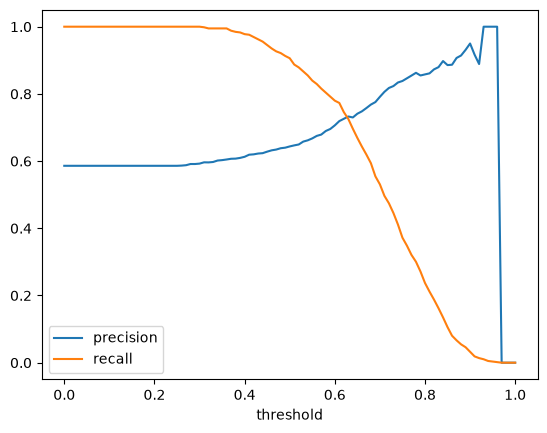

threshold    0.630000
precision    0.732759
recall       0.725256
f1           0.728988
diff         0.007503
Name: 63, dtype: float64

In [7]:
def confusion_counts(y_true, y_score, t):
    pred = y_score >= t
    actual = y_true == 1
    tp = (pred & actual).sum()
    fp = (pred & ~actual).sum()
    fn = (~pred & actual).sum()
    return tp, fp, fn

rows = []
for t in np.arange(0.0, 1.01, 0.01):
    tp, fp, fn = confusion_counts(y_val, y_pred, t)
    p = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * p * r / (p + r) if (p + r) > 0 else 0.0
    rows.append((round(t, 2), p, r, f1))

scores = pd.DataFrame(rows, columns=['threshold', 'precision', 'recall', 'f1'])

plt.plot(scores.threshold, scores.precision, label='precision')
plt.plot(scores.threshold, scores.recall, label='recall')
plt.xlabel('threshold')
plt.legend()
plt.show()

valid = scores[(scores.precision > 0) | (scores.recall > 0)].copy()
valid['diff'] = (valid.precision - valid.recall).abs()
valid.loc[valid['diff'].idxmin()]

## Question 4: F1 score

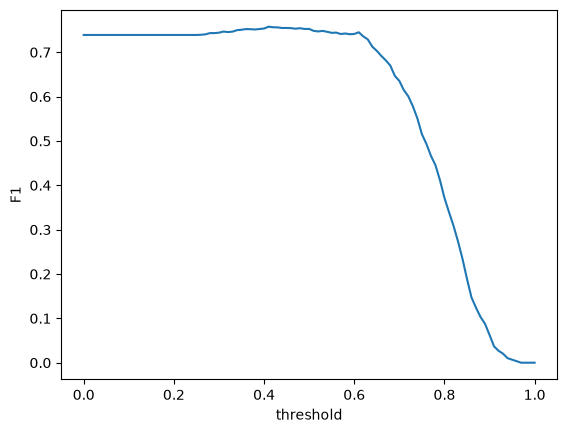

threshold    0.410000
precision    0.619048
recall       0.976109
f1           0.757616
Name: 41, dtype: float64

In [8]:
plt.plot(scores.threshold, scores.f1)
plt.xlabel('threshold')
plt.ylabel('F1')
plt.show()

scores.loc[scores.f1.idxmax()]

## Question 5: 5-Fold CV

In [9]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

aucs = []
for train_idx, val_idx in kfold.split(df_full_train):
    d_tr = df_full_train.iloc[train_idx]
    d_va = df_full_train.iloc[val_idx]
    dv_, m_ = train(d_tr, d_tr.converted.values)
    p_ = predict(d_va, dv_, m_)
    aucs.append(roc_auc_score(d_va.converted.values, p_))

print(aucs)
print('mean', round(np.mean(aucs), 3), 'std', round(np.std(aucs), 3))

[0.7305601027122453, 0.7295726148196622, 0.7363428071259397, 0.7412454717957564, 0.7209138590326581]
mean 0.732 std 0.007


## Question 6: Hyperparameter Tuning

In [10]:
results = []
for C in [0.000001, 0.001, 1]:
    aucs = []
    for train_idx, val_idx in kfold.split(df_full_train):
        d_tr = df_full_train.iloc[train_idx]
        d_va = df_full_train.iloc[val_idx]
        dv_, m_ = train(d_tr, d_tr.converted.values, C=C)
        p_ = predict(d_va, dv_, m_)
        aucs.append(roc_auc_score(d_va.converted.values, p_))
    results.append((C, round(np.mean(aucs), 3), round(np.std(aucs), 3)))

pd.DataFrame(results, columns=['C', 'mean_auc', 'std_auc'])

,C,mean_auc,std_auc
0,0.000001,0.617,0.019
1,0.001000,0.749,0.010
2,1.000000,0.732,0.007
